# Evidencia estadística: Partes 1 y 2

**Alumno:** Manuel Bajos Rivera  
**Fabricante asignado:** FAB3


In [48]:
# pip install pandas numpy matplotlib seaborn scikit-learn openpyxl statsmodels


In [49]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

localPath = 'DATA_VENTAS.xlsx'
googleColabPath = '/content/drive/MyDrive/septimoSemestre/DATA_VENTAS.xlsx'
if not os.path.exists(localPath):
    print("Running in Google Colab environment")
    from google.colab import drive
    drive.mount('/content/drive')

else:
    print("Running in local environment")
    print("Local path exists:", localPath)

if not os.path.exists(localPath):
    df = pd.read_excel(googleColabPath)
else:
    df = pd.read_excel(localPath)

Running in local environment
Local path exists: DATA_VENTAS.xlsx


# Importación de datos y organización

In [50]:
order_df = df.sort_values(by=['VENTA_VALOR'], ascending=False)
display(order_df)
#No existe fab4
print(order_df[order_df['FABRICANTE'] == 'FAB4'])

,CORTE,FABRICANTE,ID,PRODUCTO,AÑO1,SEMANA,MES,FECHAW,FECHAM,VENTA_VALOR,LITROS,PRECIO_UNITARIO_LITRO,PAQUETES,PRECIO_UNITARIO_PAQUETE,UNIDADES_EN_PAQUETE
449,TN,FAB1,Leche Clasica Deslactosada 1 L,FAB1_Leche Clasica Deslactosada 1 L,2023,37,9,2023-09-11,2023-09-01,7183943.17,364836,19.690883,30403,236.290602,12
841,TN,FAB1,Leche Clasica Entera 1 L,FAB1_Leche Clasica Entera 1 L,2024,3,1,2024-01-15,2024-01-01,5886059.29,294216,20.005912,24518,240.070939,12
453,TN,FAB1,Leche Clasica Deslactosada 1 L,FAB1_Leche Clasica Deslactosada 1 L,2023,41,10,2023-10-09,2023-10-01,5817919.05,300468,19.362857,25039,232.354289,12
843,TN,FAB1,Leche Clasica Entera 1 L,FAB1_Leche Clasica Entera 1 L,2024,5,2,2024-01-29,2024-02-01,5601744.13,277920,20.155959,23160,241.871508,12
784,TN,FAB1,Leche Clasica Entera 1 L,FAB1_Leche Clasica Entera 1 L,2022,50,12,2022-12-12,2022-12-01,5563644.75,309708,17.964162,25809,215.569947,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1998,TN,FAB2,Entera Entera 1 L,FAB2_ Entera Entera 1 L,2023,52,12,2023-12-25,2023-12-01,-500.00,-24,20.833333,-2,250.000000,12
2491,TN,FAB6,12/1L Leche Y Pan En Tera,FAB6_12/1L Leche Y Pan En Tera,2023,48,11,2023-11-27,2023-11-01,-1020.00,-60,17.000000,-5,204.000000,12
1304,TN,FAB1,Leche Clasica Semi 1 L,FAB1_Leche Clasica Semi 1 L,2023,36,9,2023-09-04,2023-09-01,-3378.01,-156,21.653910,-13,259.846923,12
3179,TN,FAB3,1L Ent Entera,FAB3_1L Ent Entera,2024,17,4,2024-04-22,2024-04-01,-489968.00,-21696,22.583333,-1808,271.000000,12


Empty DataFrame
Columns: [CORTE, FABRICANTE, ID, PRODUCTO, AÑO1, SEMANA, MES, FECHAW, FECHAM, VENTA_VALOR, LITROS, PRECIO_UNITARIO_LITRO, PAQUETES, PRECIO_UNITARIO_PAQUETE, UNIDADES_EN_PAQUETE]
Index: []


# Limpieza, revisión de nulos y organización de los datos

Antes de agregar la información se revisan los nulos, la consistencia entre los ID y los PRODUCTO y los registros con cantidades no positivas. Las tres filas con precios unitarios nulos se examinan individualmente: dos tienen volumen cero, por lo que el precio unitario no está definido, y una tiene valor de venta cero con volumen positivo, lo que produce un precio implícito de cero. Ninguno de estos casos permite calcular el logaritmo del precio. Como representan 0.091% de la base, se eliminan del análisis y se documenta su efecto en el número de filas.

La base se agrupa directamente a nivel producto-mes mediante FECHAM. El sum del groupby mensual incorpora automáticamente todas las filas del mes, incluso si una semana aparece más de una vez. No se crea una tabla semanal intermedia ni se elimina manualmente ninguna fila repetida.

Las cantidades negativas se interpretan como devoluciones y se mantienen para que los totales netos coincidan con la fuente.

In [51]:
# Conservar una copia sin modificaciones para las auditorías.
df_raw = df.copy()

print("=== REVISIÓN Y JUSTIFICACIÓN DE NULOS ===")
null_summary = df_raw.isna().sum()
display(null_summary.to_frame("NULOS"))

null_rows = df_raw.loc[df_raw.isna().any(axis=1),
                       ["FABRICANTE", "ID", "FECHAW", "VENTA_VALOR", "LITROS",
                        "PAQUETES", "PRECIO_UNITARIO_LITRO",
                        "PRECIO_UNITARIO_PAQUETE"]].copy()
null_rows["DIAGNOSTICO"] = np.where(
    (null_rows["LITROS"] == 0) | (null_rows["PAQUETES"] == 0),
    "Precio indefinido por volumen cero",
    "Precio implícito cero; log(precio) no está definido",
)
display(null_rows)

# Verificar que cada ID identifica un solo PRODUCTO y viceversa.
id_to_product = df_raw.groupby("ID")["PRODUCTO"].nunique()
product_to_id = df_raw.groupby("PRODUCTO")["ID"].nunique()
print("\n=== CONSISTENCIA ID ↔ PRODUCTO ===")
print("ID asociados con más de un PRODUCTO:", int((id_to_product > 1).sum()))
print("PRODUCTO asociados con más de un ID:", int((product_to_id > 1).sum()))

# Cinco filas son devoluciones (cantidades negativas) y dos tienen volumen cero.
nonpositive_qty = df_raw[(df_raw["LITROS"] <= 0) | (df_raw["PAQUETES"] <= 0)]
print("\n=== CANTIDADES NO POSITIVAS ===")
print("Filas con LITROS o PAQUETES no positivos:", len(nonpositive_qty))
print("Devoluciones con cantidad negativa:",
      len(nonpositive_qty[(nonpositive_qty["LITROS"] < 0) | (nonpositive_qty["PAQUETES"] < 0)]))
print("Filas con cantidad cero:",
      len(nonpositive_qty[(nonpositive_qty["LITROS"] == 0) | (nonpositive_qty["PAQUETES"] == 0)]))
display(nonpositive_qty[["FABRICANTE", "ID", "FECHAW", "VENTA_VALOR", "LITROS", "PAQUETES"]])

df = df_raw.dropna().copy()
print(f"\nFilas antes de excluir nulos: {len(df_raw):,}")
print(f"Filas después de excluir nulos: {len(df):,}")
print(f"Porcentaje excluido: {(1 - len(df) / len(df_raw)) * 100:.3f}%")


=== REVISIÓN Y JUSTIFICACIÓN DE NULOS ===


,NULOS
CORTE,0
FABRICANTE,0
ID,0
PRODUCTO,0
AÑO1,0
SEMANA,0
MES,0
FECHAW,0
FECHAM,0
VENTA_VALOR,0


,FABRICANTE,ID,FECHAW,VENTA_VALOR,LITROS,PAQUETES,PRECIO_UNITARIO_LITRO,PRECIO_UNITARIO_PAQUETE,DIAGNOSTICO
1309,FAB1,Leche Clasica Semi 1 L,2024-04-15,0.0,192,16,NaN,NaN,Precio implícito cero; log(precio) no está def...
1659,FAB2,Des Light Deslactosada Light 1L,2025-01-20,-268.0,0,0,NaN,NaN,Precio indefinido por volumen cero
3268,FAB3,1L Ent Entera,2025-04-21,0.0,0,0,NaN,NaN,Precio indefinido por volumen cero



=== CONSISTENCIA ID ↔ PRODUCTO ===
ID asociados con más de un PRODUCTO: 0
PRODUCTO asociados con más de un ID: 0

=== CANTIDADES NO POSITIVAS ===
Filas con LITROS o PAQUETES no positivos: 7
Devoluciones con cantidad negativa: 5
Filas con cantidad cero: 2


,FABRICANTE,ID,FECHAW,VENTA_VALOR,LITROS,PAQUETES
1304,FAB1,Leche Clasica Semi 1 L,2023-09-04,-3378.01,-156,-13
1659,FAB2,Des Light Deslactosada Light 1L,2025-01-20,-268.00,0,0
1998,FAB2,Entera Entera 1 L,2023-12-25,-500.00,-24,-2
2491,FAB6,12/1L Leche Y Pan En Tera,2023-11-27,-1020.00,-60,-5
2868,FAB3,1L Desl Deslactosada,2024-04-22,-1057320.00,-46992,-3916
3179,FAB3,1L Ent Entera,2024-04-22,-489968.00,-21696,-1808
3268,FAB3,1L Ent Entera,2025-04-21,0.00,0,0



Filas antes de excluir nulos: 3,296
Filas después de excluir nulos: 3,293
Porcentaje excluido: 0.091%


In [52]:
monthly_group = ["CORTE", "FABRICANTE", "ID", "PRODUCTO", "FECHAM"]
df_mensual = (df.groupby(monthly_group, as_index=False)
                .agg(VENTA_VALOR=("VENTA_VALOR", "sum"),
                     LITROS=("LITROS", "sum"),
                     PAQUETES=("PAQUETES", "sum")))

df_mensual["PRECIO_UNITARIO_LITRO"] = df_mensual["VENTA_VALOR"] / df_mensual["LITROS"]
df_mensual["PRECIO_UNITARIO_PAQUETE"] = df_mensual["VENTA_VALOR"] / df_mensual["PAQUETES"]

display(df_mensual.head(10))

print(f"Filas limpias: {len(df):,}")
print(f"Filas producto-mes: {len(df_mensual):,}")
print(f"Meses: {df_mensual['FECHAM'].nunique():,}")

order_df = df_mensual.sort_values(by="VENTA_VALOR", ascending=False)


,CORTE,FABRICANTE,ID,PRODUCTO,FECHAM,VENTA_VALOR,LITROS,PAQUETES,PRECIO_UNITARIO_LITRO,PRECIO_UNITARIO_PAQUETE
0,TN,FAB1,1L Sel Des Deslactosada,FAB1_1L Sel Des Deslactosada,2022-04-01,219798.22,11064,922,19.866072,238.392863
1,TN,FAB1,1L Sel Des Deslactosada,FAB1_1L Sel Des Deslactosada,2022-05-01,338979.66,16980,1415,19.963466,239.561597
2,TN,FAB1,1L Sel Des Deslactosada,FAB1_1L Sel Des Deslactosada,2022-06-01,687224.59,34860,2905,19.713844,236.566124
3,TN,FAB1,1L Sel Des Deslactosada,FAB1_1L Sel Des Deslactosada,2022-07-01,723623.35,36588,3049,19.777614,237.331371
4,TN,FAB1,1L Sel Des Deslactosada,FAB1_1L Sel Des Deslactosada,2022-08-01,769971.83,38580,3215,19.957798,239.493571
5,TN,FAB1,1L Sel Des Deslactosada,FAB1_1L Sel Des Deslactosada,2022-09-01,988311.90,46668,3889,21.177507,254.130085
6,TN,FAB1,1L Sel Des Deslactosada,FAB1_1L Sel Des Deslactosada,2022-10-01,938814.83,45168,3764,20.784955,249.419455
7,TN,FAB1,1L Sel Des Deslactosada,FAB1_1L Sel Des Deslactosada,2022-11-01,1184781.36,57192,4766,20.715858,248.590298
8,TN,FAB1,1L Sel Des Deslactosada,FAB1_1L Sel Des Deslactosada,2022-12-01,1159401.07,54396,4533,21.314087,255.769043
9,TN,FAB1,1L Sel Des Deslactosada,FAB1_1L Sel Des Deslactosada,2023-01-01,908234.97,43176,3598,21.035644,252.427729


Filas limpias: 3,293
Filas producto-mes: 710
Meses: 43


# Analisis
Aquí se comienza a obtener información en base al dataset que se tiene.

-------- total de ventas por fabricante --------


FABRICANTE
FAB1    9.660932e+08
FAB2    4.497632e+08
FAB3    6.913222e+08
FAB5    1.563710e+08
FAB6    2.941226e+07
Name: VENTA_VALOR, dtype: float64

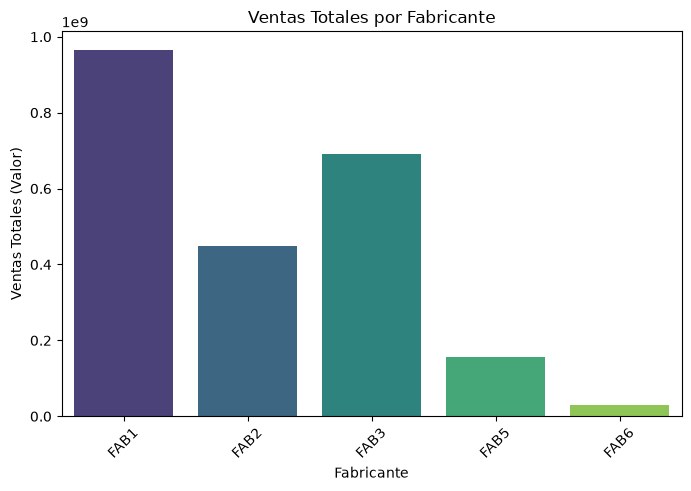

-------- total de litros por fabricante --------


FABRICANTE
FAB1    47584680
FAB2    23032956
FAB3    32931156
FAB5     8098860
FAB6     1893240
Name: LITROS, dtype: int64

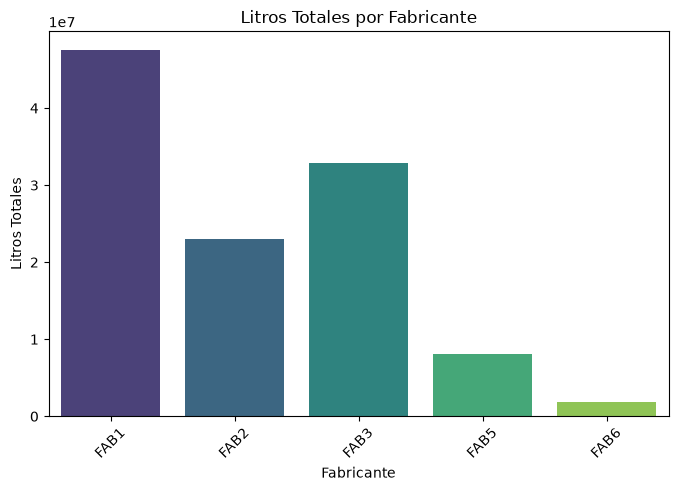

-------- total de paquetes por fabricante --------


FABRICANTE
FAB1    3965390
FAB2    1918050
FAB3    2744263
FAB5     674905
FAB6     157770
Name: PAQUETES, dtype: int64

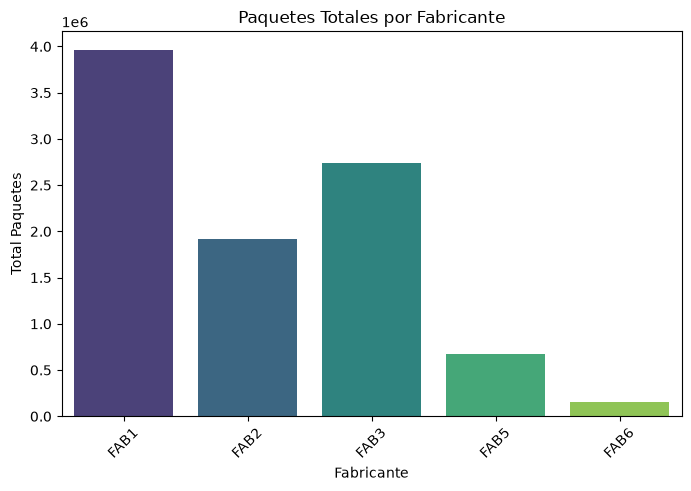

-------- productos más vendidos por fabricante --------
El producto más vendido por FAB1 es FAB1_Leche Clasica Entera 1 L
El producto más vendido por FAB3 es FAB3_1L  Ent Entera
El producto más vendido por FAB5 es FAB5_Mm 12/1L Leche Ente Members Mark
El producto más vendido por FAB2 es FAB2_ Deslac Deslactosada 1 L
El producto más vendido por FAB6 es FAB6_12/1L Leche Y Pan En Tera
-------- Productos más vendidos por FABRICANTE 3 --------


PRODUCTO
FAB3_1L  Ent Entera                 3.837791e+08
FAB3_1L  Desl Deslactosada          2.350770e+08
FAB3_1L  D Li Deslactosada Light    7.246608e+07
Name: VENTA_VALOR, dtype: float64

/var/folders/06/082vc2px7v791h689yrjpmv80000gn/T/ipykernel_37061/2853335208.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=product_sells_fab3.index, y=product_sells_fab3.values, palette='viridis')


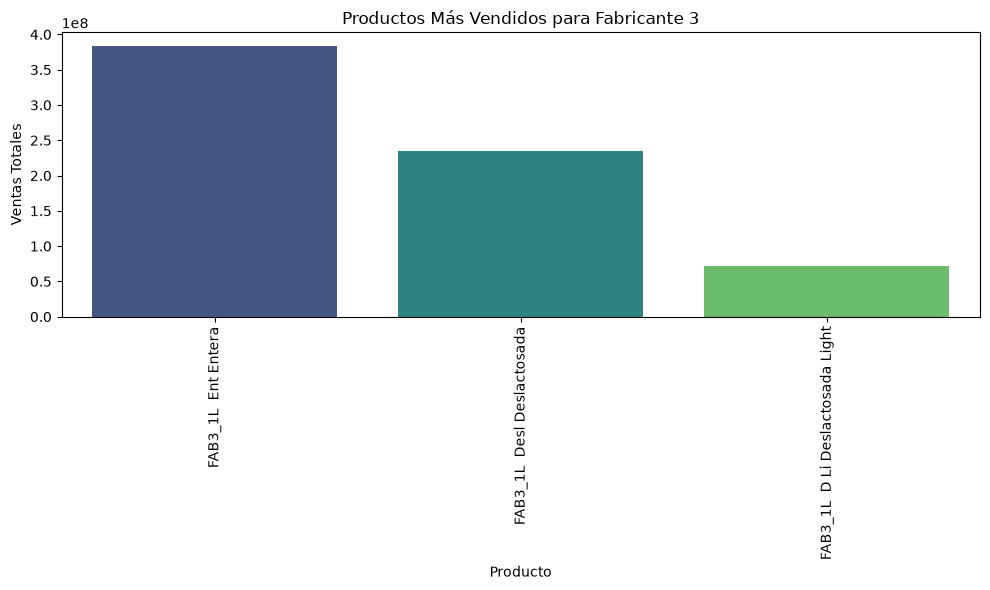

In [53]:
print("-------- total de ventas por fabricante --------")
total_sells = order_df.groupby('FABRICANTE')['VENTA_VALOR'].sum()
display(total_sells)

# Crear la gráfica de ventas
plt.figure(figsize=(8, 5))
sns.barplot(x=total_sells.index, y=total_sells.values, hue=total_sells.index, palette='viridis', legend=False)
plt.title('Ventas Totales por Fabricante')
plt.xlabel('Fabricante')
plt.ylabel('Ventas Totales (Valor)')
plt.xticks(rotation=45)
plt.show()

print("-------- total de litros por fabricante --------")
total_liters = order_df.groupby('FABRICANTE')['LITROS'].sum()
display(total_liters)

# Crear la gráfica de litros
plt.figure(figsize=(8, 5))
sns.barplot(x=total_liters.index, y=total_liters.values, hue=total_liters.index, palette='viridis', legend=False)
plt.title('Litros Totales por Fabricante')
plt.xlabel('Fabricante')
plt.ylabel('Litros Totales')
plt.xticks(rotation=45)
plt.show()

print("-------- total de paquetes por fabricante --------")
total_package = order_df.groupby('FABRICANTE')['PAQUETES'].sum()
display(total_package)

# Crear la gráfica de paquetes
plt.figure(figsize=(8, 5))
sns.barplot(x=total_package.index, y=total_package.values, hue=total_package.index, palette='viridis', legend=False)
plt.title('Paquetes Totales por Fabricante')
plt.xlabel('Fabricante')
plt.ylabel('Total Paquetes')
plt.xticks(rotation=45)
plt.show()

print("-------- productos más vendidos por fabricante --------")
for fabricante in order_df['FABRICANTE'].unique():
    top_product_sell = order_df[order_df['FABRICANTE'] == fabricante].groupby('PRODUCTO')['VENTA_VALOR'].sum().idxmax()
    print(f"El producto más vendido por {fabricante} es {top_product_sell}")

print("-------- Productos más vendidos por FABRICANTE 3 --------")
# Filter for FABRICANTE 3
fab3_df = df_mensual[df_mensual['FABRICANTE'] == 'FAB3']

# Group by PRODUCTO and sum VENTA_VALOR
product_sells_fab3 = fab3_df.groupby('PRODUCTO')['VENTA_VALOR'].sum().sort_values(ascending=False)
display(product_sells_fab3)

# Create the bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x=product_sells_fab3.index, y=product_sells_fab3.values, palette='viridis')
plt.title('Productos Más Vendidos para Fabricante 3')
plt.xlabel('Producto')
plt.ylabel('Ventas Totales')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

En el periodo completo, FAB1 concentra el mayor valor de venta y FAB3 ocupa el segundo lugar. La similitud entre las gráficas de valor, litros y paquetes es principalmente mecánica: el valor de venta depende del volumen y litros y paquetes son dos unidades del mismo movimiento. Por ello, estas relaciones no deben interpretarse como evidencia causal.

Los productos líderes del periodo completo son mayoritariamente presentaciones de leche entera o clásica; FAB2 es la excepción, con una presentación deslactosada. Para FAB3, las tres mayores ventas acumuladas corresponden a leche entera, deslactosada y deslactosada light. La elección del producto top para la regresión se vuelve a calcular más adelante sólo con los últimos 12 meses, tal como pide el enunciado.


# Objetivo 1:
Provide understanding of the milk category by manufacturer (fab) in terms of a) market share composition by year, and b) sales and price performance over time. Identify the top fabs that make 80% of the market share for the last 12 months. Show relevant descriptive statistics according to your analysis and assumptions.

Meses incluidos: 2024-08 a 2025-07


,MARKET_SHARE_PCT,ACUMULADO_PCT
FABRICANTE,,
FAB1,35.93,35.93
FAB3,28.72,64.65
FAB5,22.00,86.65
FAB2,13.35,100.00


Fabricantes que superan 80%: FAB1, FAB3, FAB5
Participación conjunta: 86.65%


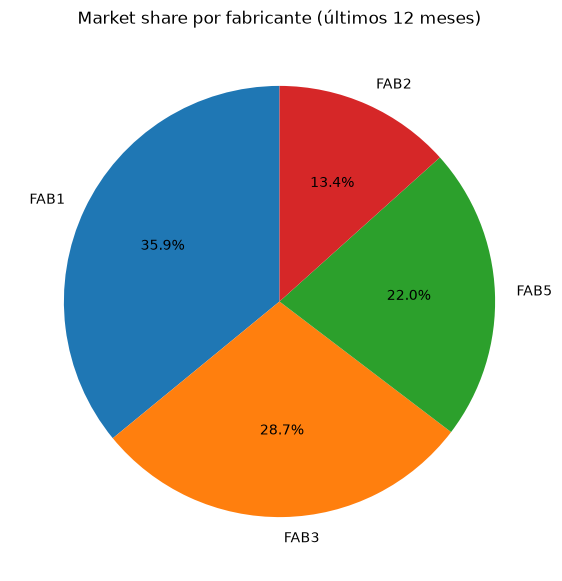

FABRICANTE,FAB1,FAB2,FAB3,FAB5,FAB6
AÑO,,,,,
2022,44.64,21.03,31.42,NaN,2.92
2023,46.43,22.65,28.93,NaN,1.99
2024,41.39,20.74,31.55,6.33,0.00
2025,33.72,11.62,27.98,26.67,NaN


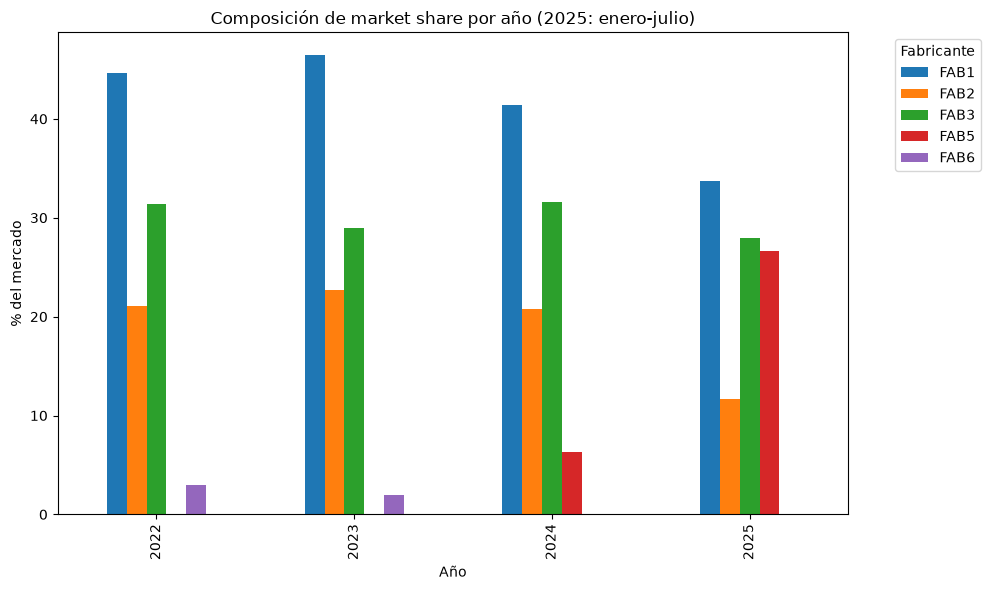

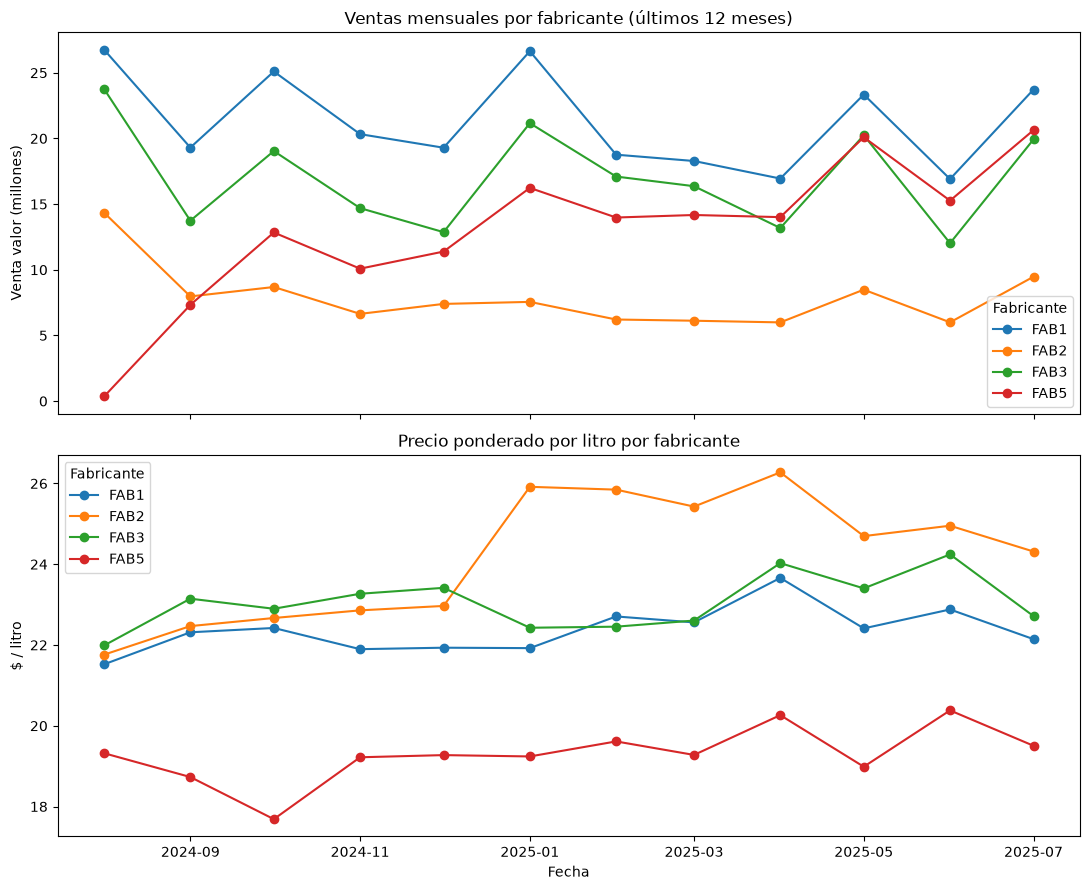

,VENTAS_U12M,MARKET_SHARE_PCT,VENTA_MENSUAL_PROM,VENTA_MENSUAL_STD,PRECIO_LITRO_POND
FABRICANTE,,,,,
FAB1,2.553917e+08,35.93,21282642.10,3637443.62,22.29
FAB2,9.488981e+07,13.35,7907484.07,2339580.52,23.81
FAB3,2.040994e+08,28.72,17008280.71,3803783.16,22.93
FAB5,1.563707e+08,22.00,13030894.04,5483060.00,19.31


In [54]:
# Fechas y ventana móvil de 12 meses: agosto de 2024 a julio de 2025.
order_df["FECHAM"] = pd.to_datetime(order_df["FECHAM"])
ultimos_12_meses = order_df["FECHAM"].drop_duplicates().sort_values().iloc[-12:]
last_months = order_df[order_df["FECHAM"].isin(ultimos_12_meses)].copy()

print("Meses incluidos:",
      f"{ultimos_12_meses.min():%Y-%m} a {ultimos_12_meses.max():%Y-%m}")

# Market share U12M y fabricantes necesarios para superar 80%.
market_share = (last_months.groupby("FABRICANTE")["VENTA_VALOR"].sum()
                / last_months["VENTA_VALOR"].sum() * 100).sort_values(ascending=False)
cumulative_share = market_share.cumsum()
n_top80 = int(np.searchsorted(cumulative_share.to_numpy(), 80) + 1)
top80_fabs = market_share.iloc[:n_top80].index.tolist()

display(pd.DataFrame({"MARKET_SHARE_PCT": market_share,
                      "ACUMULADO_PCT": cumulative_share}).round(2))
print("Fabricantes que superan 80%:", ", ".join(top80_fabs))
print(f"Participación conjunta: {market_share.iloc[:n_top80].sum():.2f}%")

plt.figure(figsize=(7, 7))
market_share.plot(kind="pie", autopct="%1.1f%%", startangle=90)
plt.title("Market share por fabricante (últimos 12 meses)")
plt.ylabel("")
plt.show()

# Composición por año. 2025 es año a la fecha (enero-julio), no un año completo.
order_df["AÑO"] = order_df["FECHAM"].dt.year
market_share_by_year = order_df.groupby(["AÑO", "FABRICANTE"])["VENTA_VALOR"].sum()
market_share_by_year_pct = market_share_by_year / market_share_by_year.groupby("AÑO").sum() * 100
market_share_pivot = market_share_by_year_pct.unstack("FABRICANTE")
display(market_share_pivot.round(2))

market_share_pivot.plot(kind="bar", figsize=(10, 6))
plt.title("Composición de market share por año (2025: enero-julio)")
plt.ylabel("% del mercado")
plt.xlabel("Año")
plt.legend(title="Fabricante", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Agregación fabricante-mes y precio ponderado: suma de valor / suma de litros.
fab_month_u12m = (last_months.groupby(["FECHAM", "FABRICANTE"], as_index=False)
                  .agg(VENTA_VALOR=("VENTA_VALOR", "sum"),
                       LITROS=("LITROS", "sum")))
fab_month_u12m["PRECIO_LITRO_POND"] = (fab_month_u12m["VENTA_VALOR"]
                                       / fab_month_u12m["LITROS"])

fig, axes = plt.subplots(2, 1, figsize=(11, 9), sharex=True)
for fab, sub in fab_month_u12m.groupby("FABRICANTE"):
    axes[0].plot(sub["FECHAM"], sub["VENTA_VALOR"] / 1e6, marker="o", label=fab)
    axes[1].plot(sub["FECHAM"], sub["PRECIO_LITRO_POND"], marker="o", label=fab)
axes[0].set_title("Ventas mensuales por fabricante (últimos 12 meses)")
axes[0].set_ylabel("Venta valor (millones)")
axes[1].set_title("Precio ponderado por litro por fabricante")
axes[1].set_ylabel("$ / litro")
axes[1].set_xlabel("Fecha")
axes[0].legend(title="Fabricante")
axes[1].legend(title="Fabricante")
plt.tight_layout()
plt.show()

# Descriptivos comparables al nivel fabricante-mes, sin mezclar tamaños de producto.
descriptivos_fab = (fab_month_u12m.groupby("FABRICANTE")
                    .agg(VENTAS_U12M=("VENTA_VALOR", "sum"),
                         VENTA_MENSUAL_PROM=("VENTA_VALOR", "mean"),
                         VENTA_MENSUAL_STD=("VENTA_VALOR", "std"),
                         LITROS_U12M=("LITROS", "sum")))
descriptivos_fab["MARKET_SHARE_PCT"] = market_share
descriptivos_fab["PRECIO_LITRO_POND"] = (
    descriptivos_fab["VENTAS_U12M"] / descriptivos_fab["LITROS_U12M"]
)
display(descriptivos_fab[["VENTAS_U12M", "MARKET_SHARE_PCT", "VENTA_MENSUAL_PROM",
                          "VENTA_MENSUAL_STD", "PRECIO_LITRO_POND"]].round(2))


### Lectura del mercado

En 2022, 2023 y 2024, FAB1 lideró con 44.64%, 46.43% y 41.39% del valor de venta, respectivamente. Entre enero y julio de 2025 su participación es 33.72%; esta cifra es acumulada del año a la fecha y no se mezcló con 2024 para “completar” el año. Para una comparación consistente se usa la ventana móvil agosto de 2024–julio de 2025: FAB1 representa 35.93%, FAB3 28.72% y FAB5 22.00%. Juntos concentran 86.65% y son los fabricantes necesarios para superar el umbral de 80%.

En los últimos 12 meses, el precio ponderado por litro fue 23.81 para FAB2, 22.93 para FAB3, 22.29 para FAB1 y 19.31 para FAB5. FAB5 combina el precio más bajo con un crecimiento fuerte de participación. Esto es compatible con una estrategia de precio y volumen, aunque la gráfica descriptiva no demuestra que el precio haya causado ese crecimiento.

Los descriptivos se calcularon a nivel fabricante-mes. Así se evita que una media global mezcle productos y presentaciones de tamaños muy distintos. La variabilidad mensual de FAB5 es mayor que la de los demás fabricantes en esta ventana; por lo tanto, no se concluye que sea el fabricante más estable sólo porque una media por registro fuera menor.


# Objetivo 2
Provide initial correlation analysis to understand important relationship within the data. You have to justify how and why you did this correlation analysis. Explain your results

Meses disponibles para las correlaciones por fabricante:


,FABRICANTE,MESES_PRECIO,MESES_VOLUMEN
0,FAB1,43,43
1,FAB2,43,43
2,FAB3,43,43
3,FAB5,13,13
4,FAB6,24,23


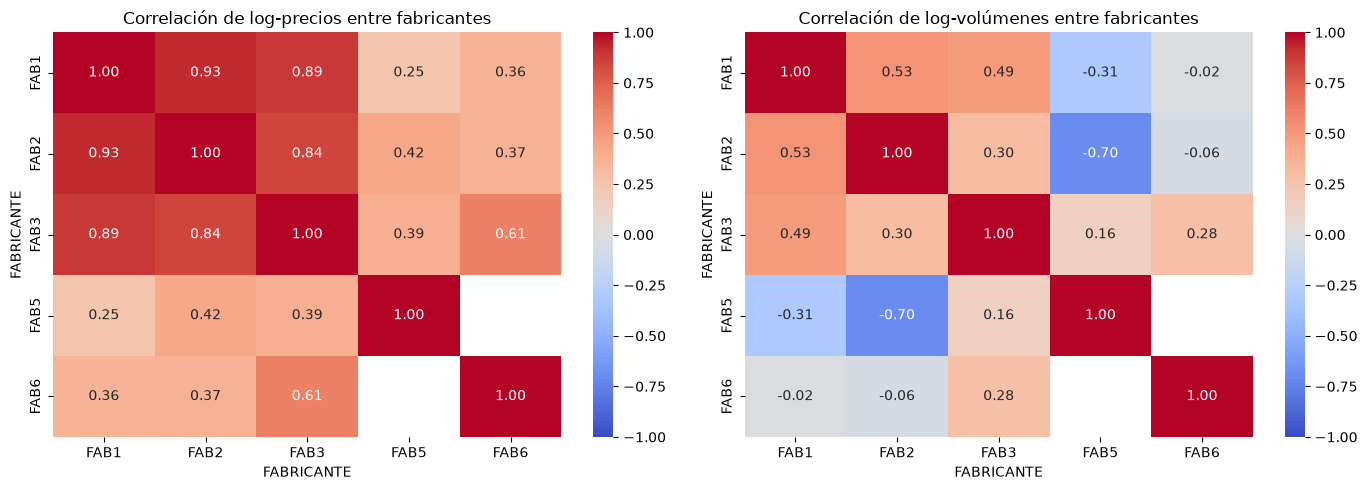

Meses comunes FAB5–FAB6 en precios: 1
Meses comunes FAB5–FAB6 en volúmenes: 1


In [55]:
# La pregunta es competitiva, por lo que primero se agrega cada fabricante en cada mes.
fab_month = (df_mensual.groupby(["FECHAM", "FABRICANTE"], as_index=False)
             .agg(VENTA_VALOR=("VENTA_VALOR", "sum"),
                  LITROS=("LITROS", "sum")))
fab_month["PRECIO_LITRO_POND"] = fab_month["VENTA_VALOR"] / fab_month["LITROS"]

# Cobertura mensual por fabricante.
manufacturers = ["FAB1", "FAB2", "FAB3", "FAB5", "FAB6"]
price_pivot = (fab_month.pivot(index="FECHAM", columns="FABRICANTE",
                               values="PRECIO_LITRO_POND")
               .reindex(columns=manufacturers))
volume_pivot = (fab_month.pivot(index="FECHAM", columns="FABRICANTE",
                                values="LITROS")
                .reindex(columns=manufacturers))

# Cada mes es una observación y cada fabricante es una variable.
log_prices = np.log(price_pivot.where(price_pivot > 0))
log_volumes = np.log(volume_pivot.where(volume_pivot > 0))
price_corr = log_prices.corr()
volume_corr = log_volumes.corr()

# DataFrame solicitado: una fila por fabricante y su número de meses válidos.
df_meses_correlacion = pd.DataFrame({
    "FABRICANTE": manufacturers,
    "MESES_PRECIO": log_prices.notna().sum().reindex(manufacturers).astype(int).to_numpy(),
    "MESES_VOLUMEN": log_volumes.notna().sum().reindex(manufacturers).astype(int).to_numpy(),
})
print("Meses disponibles para las correlaciones por fabricante:")
display(df_meses_correlacion)

# Número de meses comunes usados en cada correlación por pares.
price_common_months = (log_prices.notna().astype(int).T
                       @ log_prices.notna().astype(int))
volume_common_months = (log_volumes.notna().astype(int).T
                        @ log_volumes.notna().astype(int))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(price_corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1,
            fmt=".2f", ax=axes[0])
axes[0].set_title("Correlación de log-precios entre fabricantes")
sns.heatmap(volume_corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1,
            fmt=".2f", ax=axes[1])
axes[1].set_title("Correlación de log-volúmenes entre fabricantes")
plt.tight_layout()
plt.show()

print(f"Meses comunes FAB5–FAB6 en precios: {price_common_months.loc['FAB5', 'FAB6']}")
print(f"Meses comunes FAB5–FAB6 en volúmenes: {volume_common_months.loc['FAB5', 'FAB6']}")


### Justificación e interpretación de las correlaciones

La unidad de análisis es fabricante-mes. La cobertura se resume en df_meses_correlacion, con una fila por fabricante y columnas para los meses válidos de precio y volumen. Para calcular las correlaciones, cada mes funciona como una observación y cada fabricante como una variable. Se comparan movimientos proporcionales mediante logaritmos y se separan precios de volúmenes. Esto evita presentar como hallazgos las identidades mecánicas VENTA_VALOR = PRECIO × LITROS y la casi equivalencia entre litros y paquetes.

Las matrices incluyen FAB1, FAB2, FAB3, FAB5 y FAB6. FAB1–FAB3 tienen 43 meses comparables; sus log-precios presentan correlaciones de 0.84 FAB2-FAB3, 0.93 FAB1-FAB2 y FAB1-FAB3 presentan una correlación de 0.89, lo cual son correlaciones fuertemente positivas. FAB5 sólo tiene 13 meses con precios positivos y FAB6 tiene 24. Entre FAB5 y FAB6 existe un solo mes común, insuficiente para calcular una correlación, por eso esa celda aparece como NaN; no se omitieron del análisis. Las correlaciones de FAB5 y FAB6 con FAB1–FAB3 sí aparecen usando los meses que coinciden, donde nos FAB5 nos da las siguientes correlaciones: 0.25 con FAB1, 0.42 con FAB2 y 0.39 con FAB3; por otro lado FAB6 cuenta con las siguiente correlaciones: 0.36 con FAB1, 0.37 con FAB2 y 0.61 con FAB3. Que donde si son correlaciones positivas y algo significantes, son menores en comparación con las anteriores mencionadas.

En log-volúmenes, FAB2–FAB5 presenta una correlación de −0.700 en sus 13 meses comunes. Esto es compatible con sustitución o con tendencias opuestas de participación, pero sigue siendo descriptivo y no demuestra que FAB5 haya causado la caída de FAB2. Donde pasa algo parecido es con FAB1 y FAB5, donde tienen una correlación negativa de -0.31. Por otro lado, FAB1 presenta correlaciones positivas de 0.53 con FAB2 y de 0.49 con FAB3, por lo que sus volúmenes suelen moverse en la misma dirección con una relación moderada. FAB2 y FAB3 tienen una correlación positiva más débil de 0.30. FAB3 presenta correlaciones positivas de 0.16 con FAB5 y de 0.28 con FAB6, pero son relaciones pequeñas. Finalmente, FAB6 tiene correlaciones de -0.02 con FAB1 y de -0.06 con FAB2; al estar tan cerca de cero, no muestran una relación lineal clara. FAB5 y FAB6 continúan con un valor NaN porque sólo comparten un mes válido. En conjunto, la relación negativa más fuerte es FAB2–FAB5, seguida por FAB1–FAB5; las demás son positivas débiles o moderadas, o prácticamente nulas. Todas estas correlaciones son descriptivas y por sí solas no demuestran sustitución ni causalidad.

Una correlación alta entre un predictor y la variable objetivo puede aumentar el $R^2$. El problema aquí son los precios están altamente correlacionados entre sí. En una regresión OLS, agregar predictores nunca reduce el $R^2$ de entrenamiento y puede elevarlo, pero la multicolinealidad dificulta separar el efecto individual de cada precio. La varianza de un coeficiente se multiplica aproximadamente por $VIF_j=1/(1-R_j^2)$, donde $R_j^2$ mide qué tan bien explican los demás predictores al predictor $j$. Cuando ese valor se acerca a uno, el error estándar aumenta y el p-value suele empeorar, aunque el $R^2$ conjunto sea alto.

Los precios de competidores todavía no se incluyen en la regresión estimada del Objetivo 5; aquí se diagnostican para el diseño futuro de elasticidad cruzada. Por lo tanto, el aumento actual del error estándar del precio se debe principalmente a la muestra pequeña y a compartir variación con tendencia y 11 dummies mensuales, no a FAB5 o FAB6.


# Objetivo 3
Design and run regression model(s) to estimate price sensitivity (direct price elasticity) for the top product of your manufacturer (fab#). Identify the top product as the product that sold the most for the last 12 months. For this model, only consider the price change as explanatory variable (do not include other factors such as seasonality or tren).

You have to present the regression output for the model and provide a clear interpretation for the regression output: parameter estimates (beta coefficients), t-Statistics, pvalues, 95% confidence intervals, and R-square.

In [56]:
import statsmodels.api as sm
import numpy as np
import pandas as pd

# Identificar el producto más vendido de FAB3 en los últimos 12 meses usando el DataFrame 'last_months'
# 'last_months' ya está filtrado para los últimos 12 meses y contiene los datos mensuales
top_prod_fab3 = (last_months[last_months['FABRICANTE'] == 'FAB3']
                  .groupby('PRODUCTO')['VENTA_VALOR'].sum().idxmax())
print(f"Producto Top de FAB3 (últimos 12 meses): {top_prod_fab3}\n")

print("Tamaño de la muestra del fabricante 3 y su producto top: ",len(df_mensual[df_mensual['PRODUCTO'] == top_prod_fab3]))
# Filtrar y ordenar
data_prod = df_mensual[df_mensual['PRODUCTO'] == top_prod_fab3].copy()
data_prod = data_prod[(data_prod['LITROS'] > 0) & (data_prod['PRECIO_UNITARIO_LITRO'] > 0)]
data_prod['FECHAM'] = pd.to_datetime(data_prod['FECHAM'])
data_prod = data_prod.sort_values('FECHAM')

data_prod['log_q'] = np.log(data_prod['LITROS'])
data_prod['log_p'] = np.log(data_prod['PRECIO_UNITARIO_LITRO'])

# --- MODELO 1: Elasticidad Directa Simple --- Durbin Watson
X1 = sm.add_constant(data_prod['log_p'])
model1 = sm.OLS(data_prod['log_q'], X1).fit()

print("=== SALIDA MODELO 1: ELASTICIDAD SIMPLE ===")
print(model1.summary())

print("\n--- INTERPRETACIÓN OBJETIVO 3 ---")
print(f"Elasticidad-precio directa: {model1.params['log_p']:.4f}")
print(f"t-Statistic: {model1.tvalues['log_p']:.4f}, p-value: {model1.pvalues['log_p']:.4f}")
ci = model1.conf_int().loc['log_p']
print(f"IC 95%: [{ci[0]:.4f}, {ci[1]:.4f}]")
print(f"R²: {model1.rsquared:.4f}")

Producto Top de FAB3 (últimos 12 meses): FAB3_1L  Ent Entera

Tamaño de la muestra del fabricante 3 y su producto top:  43
=== SALIDA MODELO 1: ELASTICIDAD SIMPLE ===
                            OLS Regression Results                            
Dep. Variable:                  log_q   R-squared:                       0.323
Model:                            OLS   Adj. R-squared:                  0.306
Method:                 Least Squares   F-statistic:                     19.55
Date:                Fri, 11 Sep 2026   Prob (F-statistic):           7.05e-05
Time:                        10:57:24   Log-Likelihood:                 5.6528
No. Observations:                  43   AIC:                            -7.306
Df Residuals:                      41   BIC:                            -3.783
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t

Primero se transforman precio y litros a logaritmos. En un modelo log-log, el coeficiente de `log_p` es una elasticidad: mide el cambio porcentual promedio de la cantidad asociado con un aumento de 1% en el precio.

El coeficiente estimado es −1.7656. Por cada aumento de 1% en el precio, el volumen disminuye en promedio 1.77%. La magnitud absoluta es mayor que uno, por lo que la demanda estimada es elástica. El estadístico t es −4.4216 y el p-value es 0.0001; se rechaza $H_0:\beta_1=0$ al 5%. El intervalo de confianza de 95%, [−2.5721, −0.9592], tampoco contiene cero. El $R^2=0.3229$ indica que el precio explica 32.29% de la variación observada de log_q.

Esta estimación puede ser engañosa si se interpreta como un efecto causal. El modelo omite tendencia, estacionalidad y el número de semanas observadas por mes. Además, el precio se construye como VENTA_VALOR/LITROS: promociones, descuentos por volumen y decisiones simultáneas de precio y cantidad pueden generar endogeneidad. El Durbin–Watson de 2.183 sólo indica que no se detecta autocorrelación residual de primer orden importante; no valida la especificación completa. Por estas razones, el resultado es una asociación útil como punto de partida, no una regla causal definitiva para fijar precios.


# Objetivo 4

Para mejorar el diseño sin estimarlo todavía, propondría el siguiente modelo mensual para el producto top de FAB3:

$$
\ln(Q_t)=\alpha+\beta\ln(P^{propio}_t)+\sum_{j=1}^{J}\gamma_j\ln(P^{competidor\ j}_t)
+\delta t+\sum_{m=2}^{12}\theta_m D_{m,t}+\lambda\ln(N\_SEMANAS_t)+\varepsilon_t
$$

- $\beta$ es la elasticidad-precio propia, manteniendo constantes los precios rivales, la tendencia, la estación y la exposición del mes. Se espera $\beta<0$.
- $\gamma_j$ es la elasticidad cruzada. Un signo positivo es compatible con productos sustitutos: si el rival sube 1% su precio, el volumen propio aumentaría $\gamma_j$%. Un signo negativo sería compatible con complementarios. Esto permite simular si conviene cambiar el precio ante un movimiento de un competidor.
- $t=1,2,3,\ldots$ captura crecimiento o caída gradual que no se debe al precio (tendencia temporal). Donde si el coeficiente es mayor a 0 tenemos una tendencia creciente, donde sea menor sería el caso contrario y si es igual a 0 no existe una tendencia lineal en el producto. 
- $D_{m,t}$ contiene 11 dummies mensuales; enero es la categoría de referencia. Se usan 11 y no 12 para evitar colinealidad perfecta con la constante.
- $\ln(N\_SEMANAS_t)$ controla que un mes con cinco semanas observadas ofrece más días de venta que uno con cuatro.

La principal dificultad es la multicolinealidad: los log-precios de FAB1, FAB2 y FAB3 tienen correlaciones de 0.844 a 0.926, por lo que suelen aumentar o disminuir al mismo tiempo. Si se incluyen los precios de todos los competidores por separado, el modelo tendrá dificultad para identificar qué parte del cambio en ventas corresponde a cada fabricante y los coeficientes pueden volverse inestables. Para reducir este problema se puede utilizar una sola variable de precio relativo: $\ln(P^{propio}_t/P^{categoría}_t)$. El precio de categoría sería el promedio ponderado de los precios de los competidores, excluyendo el producto propio. Si esta razón aumenta, significa que el producto propio se volvió relativamente más caro que el resto de la categoría; si disminuye, se volvió relativamente más barato. Esta variable resume la posición de precio frente al mercado y evita agregar un coeficiente diferente para cada competidor. Como sólo existen 43 observaciones, usar menos variables permite conservar más grados de libertad. También se podrían seleccionar únicamente los competidores más relevantes.


# Objetivo 5
For your model (of the top product), add variables to include the effects of seasonality and growing volume trend.

In [66]:
# Objetivo 5: modelo múltiple y comparación con el modelo simple
import statsmodels.api as sm

# Misma muestra de 43 meses y mismo producto top que en el modelo simple.
data_obj5 = data_prod.copy().sort_values("FECHAM")
data_obj5["trend"] = np.arange(1, len(data_obj5) + 1)
data_obj5["month"] = data_obj5["FECHAM"].dt.month

# La exposición semanal se calcula sólo aquí, donde la necesita el modelo.
# Se cuentan fechas semanales distintas del producto top dentro de cada FECHAM.
weeks_for_top_product = (
    df.loc[df["PRODUCTO"] == top_prod_fab3]
      .assign(FECHAM=lambda x: pd.to_datetime(x["FECHAM"]))
      .groupby("FECHAM")["FECHAW"]
      .nunique()
      .rename("SEMANAS_EN_MES")
)
data_obj5 = data_obj5.merge(weeks_for_top_product, on="FECHAM", how="left",
                            validate="one_to_one")
data_obj5["log_n_semanas"] = np.log(data_obj5["SEMANAS_EN_MES"])

month_dummies = pd.get_dummies(data_obj5["month"], prefix="month",
                               drop_first=True, dtype=float)
y = data_obj5["log_q"]

# A) Modelo múltiple solicitado: precio + tendencia + 11 dummies mensuales.
X_required = sm.add_constant(pd.concat([
    data_obj5[["log_p", "trend"]].astype(float), month_dummies
], axis=1))
model_extended_ols = sm.OLS(y, X_required).fit()
model_extended_hac = sm.OLS(y, X_required).fit(
    cov_type="HAC", cov_kwds={"maxlags": 3}, use_t=True
)

# B) Modelo múltiple con corrección de calendario y errores Newey-West.
X_calendar = sm.add_constant(pd.concat([
    data_obj5[["log_p", "log_n_semanas", "trend"]].astype(float), month_dummies
], axis=1))
model_calendar_ols = sm.OLS(y, X_calendar).fit()
model_calendar_hac = sm.OLS(y, X_calendar).fit(
    cov_type="HAC", cov_kwds={"maxlags": 3}, use_t=True
)

print("=== MODELO MÚLTIPLE: PRECIO + TENDENCIA + ESTACIONALIDAD ===")
print(model_extended_ols.summary())

print("Meses por número de semanas observadas para el producto top:")
display(data_obj5["SEMANAS_EN_MES"].value_counts().sort_index().rename("MESES").to_frame())
assert data_obj5["SEMANAS_EN_MES"].notna().all()
assert set(data_obj5["SEMANAS_EN_MES"].unique()).issubset({4, 5})

print("=== MODELO MÚLTIPLE CON log(N_SEMANAS) Y ERRORES HAC ===")
print(model_calendar_hac.summary())

# Comparación directa con el modelo simple estimado en el Objetivo 3.
comparison = pd.DataFrame({
    "Modelo simple anterior": {
        "Elasticidad precio": model1.params["log_p"],
        "Error estándar precio": model1.bse["log_p"],
        "p-value precio": model1.pvalues["log_p"],
        "IC 95% inferior": model1.conf_int().loc["log_p", 0],
        "IC 95% superior": model1.conf_int().loc["log_p", 1],
        "R^2": model1.rsquared,
        "R^2 ajustado": model1.rsquared_adj,
    },
    "Modelo múltiple": {
        "Elasticidad precio": model_extended_ols.params["log_p"],
        "Error estándar precio": model_extended_ols.bse["log_p"],
        "p-value precio": model_extended_ols.pvalues["log_p"],
        "IC 95% inferior": model_extended_ols.conf_int().loc["log_p", 0],
        "IC 95% superior": model_extended_ols.conf_int().loc["log_p", 1],
        "R^2": model_extended_ols.rsquared,
        "R^2 ajustado": model_extended_ols.rsquared_adj,
    },
    "Modelo múltiple + log(N_SEMANAS), HAC": {
        "Elasticidad precio": model_calendar_hac.params["log_p"],
        "Error estándar precio": model_calendar_hac.bse["log_p"],
        "p-value precio": model_calendar_hac.pvalues["log_p"],
        "IC 95% inferior": model_calendar_hac.conf_int().loc["log_p", 0],
        "IC 95% superior": model_calendar_hac.conf_int().loc["log_p", 1],
        "R^2": model_calendar_hac.rsquared,
        "R^2 ajustado": model_calendar_hac.rsquared_adj,
    },
}).T

print("\n=== COMPARACIÓN CON EL MODELO ANTERIOR ===")
display(comparison.round(4))

change_vs_simple = pd.Series({
    "Cambio en elasticidad (múltiple - simple)": (
        model_extended_ols.params["log_p"] - model1.params["log_p"]
    ),
    "Cambio en R² (múltiple - simple)": model_extended_ols.rsquared - model1.rsquared,
    "Cambio en R² ajustado (múltiple - simple)": (
        model_extended_ols.rsquared_adj - model1.rsquared_adj
    ),
    "Multiplicador del error estándar del precio": (
        model_extended_ols.bse["log_p"] / model1.bse["log_p"]
    ),
})
display(change_vs_simple.round(4).rename("RESULTADO").to_frame())

calendar_effect = (np.exp(model_calendar_hac.params["log_n_semanas"] * np.log(5 / 4)) - 1) * 100
print(f"Efecto estimado de pasar de 4 a 5 semanas: {calendar_effect:.1f}%")
print(f"Durbin-Watson del modelo múltiple: {sm.stats.stattools.durbin_watson(model_extended_ols.resid):.3f}")
print(f"Durbin-Watson del modelo con semanas: {sm.stats.stattools.durbin_watson(model_calendar_ols.resid):.3f}")

model_final = model_extended_ols


=== MODELO MÚLTIPLE: PRECIO + TENDENCIA + ESTACIONALIDAD ===
                            OLS Regression Results                            
Dep. Variable:                  log_q   R-squared:                       0.517
Model:                            OLS   Adj. R-squared:                  0.301
Method:                 Least Squares   F-statistic:                     2.390
Date:                Fri, 11 Sep 2026   Prob (F-statistic):             0.0250
Time:                        11:15:01   Log-Likelihood:                 12.928
No. Observations:                  43   AIC:                             2.144
Df Residuals:                      29   BIC:                             26.80
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------

,MESES
SEMANAS_EN_MES,
4,28
5,15


=== MODELO MÚLTIPLE CON log(N_SEMANAS) Y ERRORES HAC ===
                            OLS Regression Results                            
Dep. Variable:                  log_q   R-squared:                       0.700
Model:                            OLS   Adj. R-squared:                  0.551
Method:                 Least Squares   F-statistic:                     30.47
Date:                Fri, 11 Sep 2026   Prob (F-statistic):           3.08e-13
Time:                        11:15:01   Log-Likelihood:                 23.188
No. Observations:                  43   AIC:                            -16.38
Df Residuals:                      28   BIC:                             10.04
Df Model:                          14                                         
Covariance Type:                  HAC                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------

,Elasticidad precio,Error estándar precio,p-value precio,IC 95% inferior,IC 95% superior,R^2,R^2 ajustado
Modelo simple anterior,-1.7656,0.3993,0.0001,-2.5721,-0.9592,0.3229,0.3064
Modelo múltiple,-2.2831,1.4678,0.1307,-5.2851,0.7190,0.5173,0.3009
"Modelo múltiple + log(N_SEMANAS), HAC",-1.5197,1.0954,0.1763,-3.7635,0.7241,0.7005,0.5507


,RESULTADO
Cambio en elasticidad (múltiple - simple),-0.5175
Cambio en R² (múltiple - simple),0.1944
Cambio en R² ajustado (múltiple - simple),-0.0055
Multiplicador del error estándar del precio,3.6758


Efecto estimado de pasar de 4 a 5 semanas: 28.5%
Durbin-Watson del modelo múltiple: 1.834
Durbin-Watson del modelo con semanas: 1.388



1. Elasticidad: El modelo simple anterior estima −1.7656. En el modelo múltiple con tendencia y estacionalidad pasa a −2.2831, un cambio de −0.5175 y un aumento cercano a 29% en magnitud. Al incorporar log(N_SEMANAS), la elasticidad estimada es −1.5197.

2. Significancia y precisión: En el modelo simple, el error estándar es 0.3993 y p = 0.0001. En el múltiple, el error estándar aumenta 3.68 veces, hasta 1.4678, y p sube a 0.1307. Su intervalo [−5.2851, 0.7190] contiene cero. Con log(N_SEMANAS) y errores HAC, p = 0.1763 y el intervalo [−3.7635, 0.7241] también contiene cero. Por tanto, la evidencia estadística se debilita al separar los efectos temporales.

3. Ajuste: El $R^2$ aumenta de 0.323 a 0.517, una diferencia de 0.194. Sin embargo, el $R^2$ ajustado cambia de 0.306 a 0.301, prácticamente no mejora porque el modelo múltiple utiliza 13 regresores. Al añadir log(N_SEMANAS), el $R^2$ llega a 0.700 y el ajustado a 0.551.

4. Tendencia y estacionalidad: En el modelo múltiple, trend = 0.0066 equivale aproximadamente a 0.66% de crecimiento mensual, pero no es significativo (p = 0.477). Ninguna dummy mensual del modelo OLS difiere significativamente de enero al 5%.

5. Diferencia entre meses de cuatro y cinco semanas: Hay 28 meses con cuatro semanas observadas y 15 con cinco. log(N_SEMANAS) se incluye porque un mes con cinco semanas tiene 25% más exposición temporal que uno de cuatro. Su coeficiente es 1.1237: el cambio de cuatro a cinco semanas se asocia con aproximadamente 28.5% más volumen, manteniendo constantes precio, tendencia y mes.

El modelo múltiple con tendencia, estacionalidad y log(N_SEMANAS) es preferible porque permite analizar la relación entre precio y volumen después de tomar en cuenta otros factores que también cambian las ventas. En otras palabras, el efecto del precio se estima comparando meses con una tendencia, una estacionalidad y un número de semanas semejantes. Este modelo utiliza errores HAC de Newey–West con tres rezagos. Los errores HAC no cambian los coeficientes ni el $R^2$; corrigen los errores estándar, los intervalos de confianza y los p-values cuando puede existir heterocedasticidad o autocorrelación en los residuos. Con esta corrección, la elasticidad del precio es −1.5197 y su p-value es 0.1763, mayor que 0.05, por lo que no existe evidencia suficiente para afirmar que el precio tiene un efecto estadísticamente significativo en este modelo. El Durbin–Watson se presenta únicamente como un diagnóstico de autocorrelación de primer orden y no demuestra por sí solo que el modelo esté correctamente especificado.


# Objetivo 6: pronóstico de precio y ventas a 24 meses

Con sólo 43 observaciones mensuales, usaría una estrategia parsimoniosa y la compararía fuera de muestra:

1. **Precio.** Empezaría con un random walk con deriva y un ARIMA sencillo como referencias. También probaría un modelo con precio de categoría o inflación si esas variables están disponibles. Cada trayectoria de precio debe incluir intervalos de predicción.
2. **Demanda.** Usaría SARIMAX con el precio pronosticado como variable exógena, tendencia, estacionalidad parsimoniosa y número de semanas. Un escenario base, uno de precio alto y otro de precio bajo mostrarían que el pronóstico de ventas depende del pronóstico previo del precio.
3. **Validación.** Haría backtesting con origen móvil y mediría MAE, RMSE y MAPE frente a referencias simples, por ejemplo último valor y promedio estacional. Para un horizonte de 24 meses, los intervalos deben ampliarse para reflejar la incertidumbre acumulada de las dos etapas.

XGBoost o Prophet pueden compararse como modelos adicionales, pero 43 puntos limitan mucho su entrenamiento y favorecen el sobreajuste. XGBoost puede predecir con variables correlacionadas, pero no resuelve la interpretación: la importancia se reparte de forma inestable entre predictores similares. LSTM y DeepAR no son apropiados para una sola serie tan corta; sólo tendrían sentido en un modelo global entrenado con cientos de observaciones provenientes de muchos productos comparables.

La selección final no se basaría en el ajuste dentro de muestra, sino en el error de backtesting, la estabilidad de los parámetros y la cobertura de los intervalos de predicción.


Para proyectar el comportamiento de **FAB3_1L Ent Entera**, se proponen tres enfoques principales, escalando en complejidad y capacidad de captura de patrones:

#### 1. Modelos de Series de Tiempo Clásicos (Estadísticos)
*   **SARIMAX (Seasonal AutoRegressive Integrated Moving Average with eXogenous factors):**
    *   **Por qué:** Es el estándar para datos con estacionalidad clara. Permite incluir el **precio** como una variable exógena para ver cómo su evolución futura afectaría las ventas.
    *   **Uso:** Ideal para capturar la inercia de ventas y los ciclos mensuales.

#### 2. Modelos de Machine Learning (Supervisado)
*   **XGBoost (Gradient Boosting Regressors):**
    *   **Por qué:** Son extremadamente robustos para manejar relaciones no lineales y pueden procesar múltiples variables (precios de la competencia, festividades, indicadores económicos) sin los problemas de multicolinealidad que afectan a la regresión OLS.
    *   **Propuesta:** Crear variables de 'lag' (ventas de meses anteriores) y ventanas móviles para predecir el siguiente periodo.
*   **Prophet (desarrollado por Meta):**
    *   **Por qué:** Está diseñado específicamente para pronósticos de negocios con datos mensuales/diarios. Maneja automáticamente los huecos en los datos, los cambios de tendencia y los efectos de días feriados.

#### 3. Enfoques de Inteligencia Artificial / Deep Learning
*   **LSTM (Long Short-Term Memory):**
    *   **Por qué:** Es un tipo de Red Neuronal Recurrente (RNN) capaz de aprender dependencias a largo plazo. Es útil si sospechamos que eventos de hace un año influyen fuertemente en el presente de una manera que los modelos lineales no captan.
*   **DeepAR (Amazon Forecasting):**
    *   **Por qué:** Utiliza redes neuronales para producir pronósticos probabilísticos. En lugar de dar un solo número, entrega rangos de incertidumbre, lo cual es vital para la planeación de inventarios a 24 meses.

### Estrategia de Implementación Recomendada
1.  **Forecast de Precio:** Primero, modelar el precio como un proceso de *Random Walk* con deriva o basado en la inflación proyectada.
2.  **Forecast de Ventas:** Utilizar el precio proyectado como entrada en un modelo **SARIMAX** o **Prophet** para obtener la demanda esperada.
3.  **Evaluación:** Utilizar una validación cruzada de series de tiempo (*Backtesting*) para medir el error (MAE/RMSE) antes de confiar en la proyección a largo plazo.